In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df= pd.read_csv('FoodDelivery.csv')

In [7]:
import pandas as pd

df = pd.read_csv('FoodDelivery.csv')
df.columns = df.columns.str.strip().str.lower()

# City-wise number of orders
print("Orders per city:\n", df['city'].value_counts())

# City-wise average order amount
amount_col = [col for col in df.columns if 'amount' in col or 'total' in col or 'price' in col][0]
print("\nAverage order amount per city:\n", df.groupby('city')[amount_col].mean())


Orders per city:
 city
Bangalore    1297
Chennai      1283
Delhi        1274
Ahmedabad    1270
Hyderabad    1246
Kolkata      1237
Pune         1197
Mumbai       1196
Name: count, dtype: int64

Average order amount per city:
 city
Ahmedabad    624.086961
Bangalore    622.237417
Chennai      626.508737
Delhi        618.577551
Hyderabad    624.075465
Kolkata      630.954834
Mumbai       623.321020
Pune         629.300334
Name: order amount, dtype: float64


In [9]:
# Standardize column names
df.columns = df.columns.str.strip().str.lower()

# Identify amount column
amount_col = [col for col in df.columns if 'amount' in col or 'total' in col or 'price' in col][0]

# Most popular cuisines overall
print("Most popular cuisines overall:\n", df['cuisine'].value_counts())

# Most popular cuisines per city
print("\nMost popular cuisines per city:\n", df.groupby('city')['cuisine'].agg(lambda x: x.value_counts().idxmax()))

# Highest revenue-generating meal type
print("\nMeal type with highest revenue:\n", df.groupby('meal type')[amount_col].sum().sort_values(ascending=False))


Most popular cuisines overall:
 cuisine
Indian      1753
Mexican     1673
American    1671
Chinese     1643
Thai        1643
Italian     1617
Name: count, dtype: int64

Most popular cuisines per city:
 city
Ahmedabad      Indian
Bangalore     Chinese
Chennai      American
Delhi            Thai
Hyderabad    American
Kolkata        Indian
Mumbai         Indian
Pune          Mexican
Name: cuisine, dtype: object

Meal type with highest revenue:
 meal type
Dinner       1581086.11
Breakfast    1579494.69
Lunch        1544462.00
Snacks       1543321.68
Name: order amount, dtype: float64


delivery mode
Express Delivery     24.881663
Pickup               14.902594
Standard Delivery    39.989946
Name: delivery time (mins), dtype: float64
                      delivery time (mins)    rating
delivery time (mins)              1.000000  0.007817
rating                            0.007817  1.000000


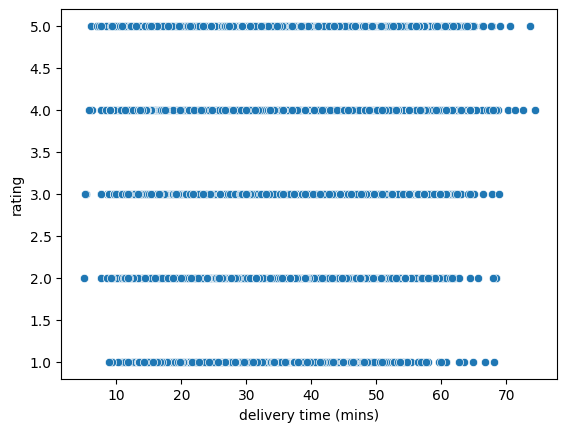

In [13]:
df.columns = df.columns.str.strip().str.lower()

# Replace these with your actual column names if different
time_col = [c for c in df.columns if 'time' in c][0]
rating_col = [c for c in df.columns if 'rating' in c][0]

print(df.groupby('delivery mode')[time_col].mean())
print(df[[time_col, rating_col]].corr())
sns.scatterplot(x=time_col, y=rating_col, data=df)
plt.show()

In [15]:
df.columns = df.columns.str.lower().str.strip()

# Identify relevant columns
discount_col = [c for c in df.columns if 'discount' in c][0]
amount_col = [c for c in df.columns if 'amount' in c or 'total' in c or 'price' in c][0]
rating_col = [c for c in df.columns if 'rating' in c][0]

# Correlation between discount, order value, and rating
print(df[[discount_col, amount_col, rating_col]].corr()[discount_col])

# Compare average ratings for high vs low discount orders
threshold = df[discount_col].quantile(0.75)
high_disc_ratings = df[df[discount_col] >= threshold][rating_col].mean()
low_disc_ratings = df[df[discount_col] < threshold][rating_col].mean()

print(f"\nAvg rating (high discount): {high_disc_ratings:.2f}")
print(f"Avg rating (low discount): {low_disc_ratings:.2f}")


discount        1.000000
order amount   -0.164472
rating         -0.010205
Name: discount, dtype: float64

Avg rating (high discount): 3.62
Avg rating (low discount): 3.66


In [16]:
df.columns = df.columns.str.lower().str.strip()

# Identify payment and amount columns
payment_col = [c for c in df.columns if 'payment' in c][0]
amount_col = [c for c in df.columns if 'amount' in c or 'total' in c or 'price' in c][0]

# Distribution of payment methods
print(df[payment_col].value_counts())

# Average order value by payment method
print(df.groupby(payment_col)[amount_col].mean())


payment method
Credit Card    2523
Debit Card     2501
UPI            2501
Wallet         1457
Cash           1018
Name: count, dtype: int64
payment method
Cash           619.773890
Credit Card    630.892564
Debit Card     627.635450
UPI            622.138049
Wallet         617.713933
Name: order amount, dtype: float64


In [17]:
df.columns = df.columns.str.lower().str.strip()

# Identify customer ID and amount columns
cust_col = [c for c in df.columns if 'customer' in c and ('id' in c or 'no' in c)][0]
amount_col = [c for c in df.columns if 'amount' in c or 'total' in c or 'price' in c][0]

# Count orders per customer
order_counts = df[cust_col].value_counts()

# Repeat vs one-time customers
repeat = (order_counts > 1).sum()
one_time = (order_counts == 1).sum()
print(f"Repeat customers: {repeat}\nOne-time customers: {one_time}")

# Top 20% customers by revenue contribution
cust_revenue = df.groupby(cust_col)[amount_col].sum()
top_20_pct = cust_revenue.quantile(0.8)
top_customers_revenue = cust_revenue[cust_revenue >= top_20_pct].sum()
total_revenue = cust_revenue.sum()
print(f"Top 20% customers contribute {top_customers_revenue / total_revenue:.2%} of total revenue")


Repeat customers: 998
One-time customers: 2
Top 20% customers contribute 30.73% of total revenue


In [18]:
df.columns = df.columns.str.lower().str.strip()

# Convert order date to datetime (adjust column name if needed)
date_col = [c for c in df.columns if 'date' in c][0]
df[date_col] = pd.to_datetime(df[date_col])

# Extract month name
df['month'] = df[date_col].dt.month_name()

# Monthly order counts
print(df['month'].value_counts().sort_index())

# Average ratings per month
rating_col = [c for c in df.columns if 'rating' in c][0]
print(df.groupby('month')[rating_col].mean().sort_index())


month
April        831
August       833
December     821
February     807
January      879
July         835
June         828
March        867
May          853
November     788
October      836
September    822
Name: count, dtype: int64
month
April        3.583634
August       3.651861
December     3.635810
February     3.675341
January      3.638225
July         3.634731
June         3.678744
March        3.608997
May          3.691676
November     3.680203
October      3.691388
September    3.628954
Name: rating, dtype: float64


OTHER IDEAS FOR DATA SET

Monthly Orders Trend with Plot

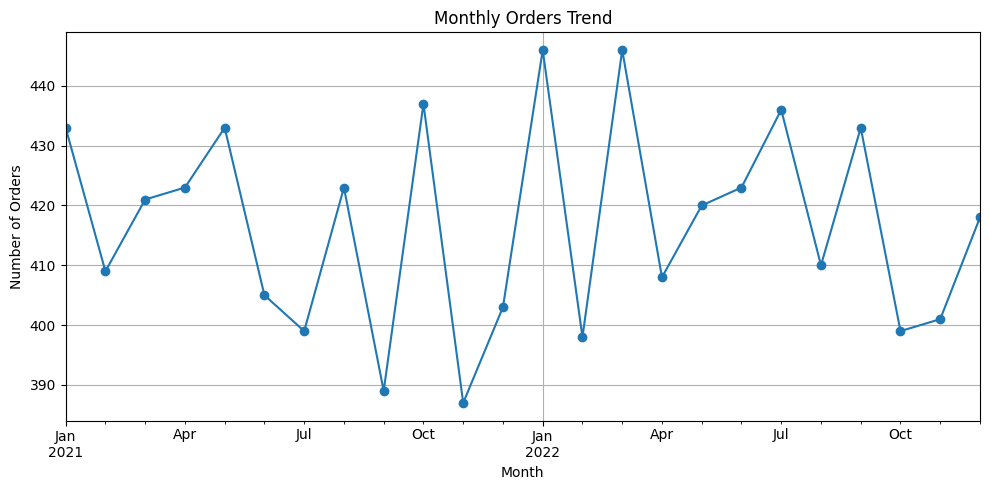

In [32]:
import pandas as pd
import matplotlib.pyplot as plt

# Standardize column names
df.columns = df.columns.str.lower().str.strip()

# Convert 'order date' to datetime and extract month
df['order date'] = pd.to_datetime(df['order date'])
df['month'] = df['order date'].dt.to_period('M')  # YYYY-MM format

# Calculate monthly order counts
monthly_stats = df.groupby('month').agg(orders=('order id', 'count'))

# Plot
monthly_stats['orders'].plot(kind='line', marker='o', figsize=(10,5), title='Monthly Orders Trend')
plt.xlabel('Month')
plt.ylabel('Number of Orders')
plt.grid(True)
plt.tight_layout()
plt.show()


Meal Type Revenue & Popularity

           total_orders  total_revenue
meal type                             
Dinner             2546     1581086.11
Breakfast          2508     1579494.69
Lunch              2463     1544462.00
Snacks             2483     1543321.68


C:\Users\yadav\AppData\Local\Temp\ipykernel_3068\326996280.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=meal_stats.index, y=meal_stats['total_revenue'], palette='YlOrBr')


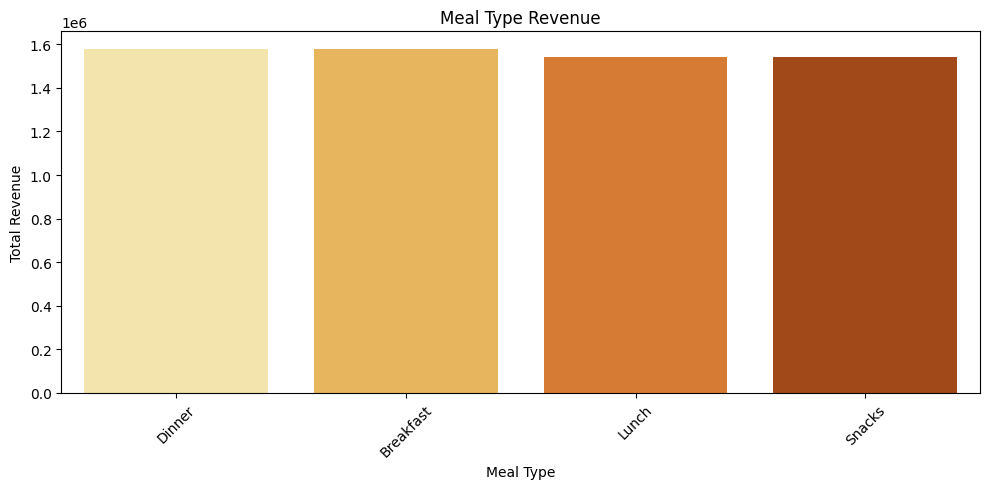

C:\Users\yadav\AppData\Local\Temp\ipykernel_3068\326996280.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=meal_stats.index, y=meal_stats['total_orders'], palette='Blues')


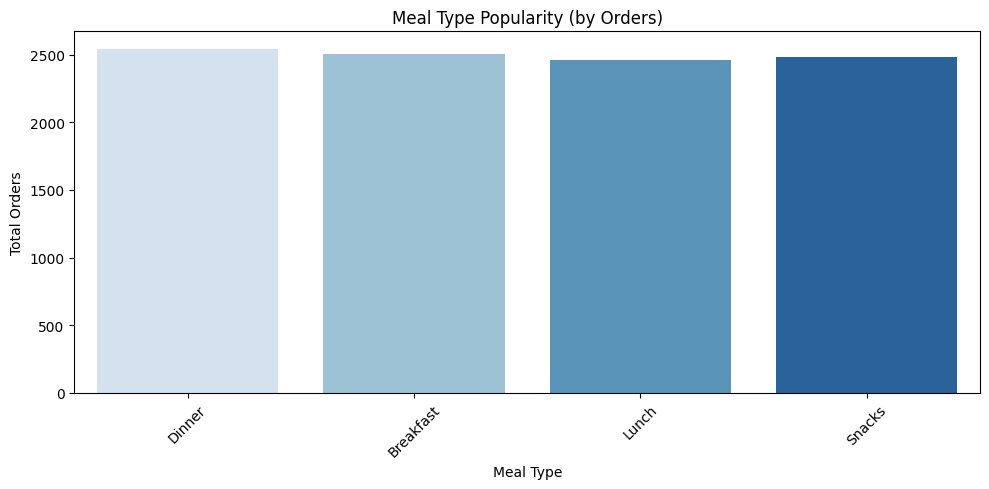

In [44]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load data
df = pd.read_csv('FoodDelivery.csv')

# Standardize column names
df.columns = df.columns.str.lower().str.strip()

# Group by Meal Type
meal_stats = df.groupby('meal type').agg(
    total_orders=('order id', 'count'),
    total_revenue=('order amount', 'sum')
).sort_values(by='total_revenue', ascending=False)

# Display stats
print(meal_stats)

# Plot Revenue
plt.figure(figsize=(10, 5))
sns.barplot(x=meal_stats.index, y=meal_stats['total_revenue'], palette='YlOrBr')
plt.title('Meal Type Revenue')
plt.ylabel('Total Revenue')
plt.xlabel('Meal Type')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Plot Orders
plt.figure(figsize=(10, 5))
sns.barplot(x=meal_stats.index, y=meal_stats['total_orders'], palette='Blues')
plt.title('Meal Type Popularity (by Orders)')
plt.ylabel('Total Orders')
plt.xlabel('Meal Type')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
